<a href="https://colab.research.google.com/github/cfs-at-ada/5838387-DataScience-GenAI-Submissions/blob/main/Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 3 – Exercise #2: EDA of the Titanic Dataset

In this notebook we perform an Exploratory Data Analysis (EDA) on "titanic.csv", following the EDA process from the slides:

1. **Univariate analysis** – analyse / visualise each variable
2. **Bivariate analysis** – compare variables for patterns (especially with `Survived`)
3. **Outliers & extreme values** – check for them
4. **Missing values** – check for them and replace
5. **Feature engineering**

> 💡 The aim is to have a "conversation with the data": read the output after every cell and briefly answer the questions in the 📝 cells.

## 0. Importing the Data
As in the EDA notebook, we import the libraries and upload the data (select "titanic.csv"):

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving titanic.csv to titanic (1).csv


We can now import the data into pandas as before:

In [7]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### First Overview
We can find the number of rows and columns with ".shape":

In [8]:
titanic.shape

(891, 12)

We can get information about the data using the _info_ function:

In [9]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Let's check for missing data:

In [10]:
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


To decide whether it is sensible to delete a column, we look at the percentage of each column's data that is missing:

In [11]:
# Percent of data which is not available
titanic.isnull().sum()/len(titanic) * 100

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


We can find the number of unique and duplicated rows:

In [12]:
titanic.duplicated().value_counts()

,count
False,891


Pandas will also give us summary statistics – first for the numeric columns, then for the text (object) columns:

In [13]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [14]:
titanic.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


📝 **Questions:**
- Which columns have missing values, and how many? Which column is almost empty?
- Which columns are actually *categorical*, even though they are stored as numbers (hint: `Pclass`, `Survived`)?
- What do you notice about `Fare` (min/max)?

## 1. Univariate Analysis
### Categorical Variables

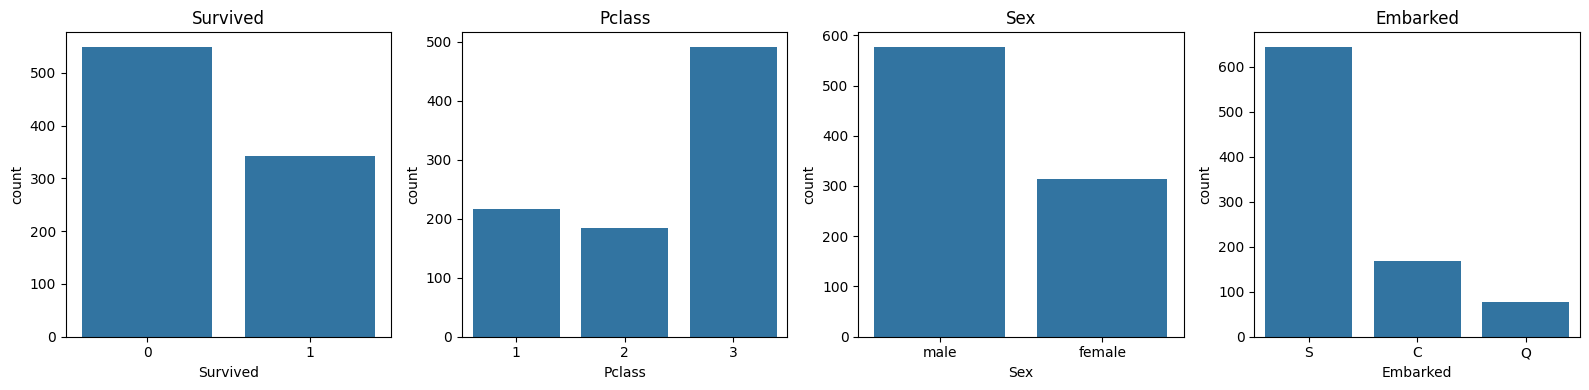

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['Survived', 'Pclass', 'Sex', 'Embarked']):
    sns.countplot(data=titanic, x=col, ax=ax) # count of passengers per category
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [16]:
titanic['Survived'].value_counts(normalize=True) * 100 # percentage survived / died

,proportion
Survived,
0,61.616162
1,38.383838


### Numeric Variables

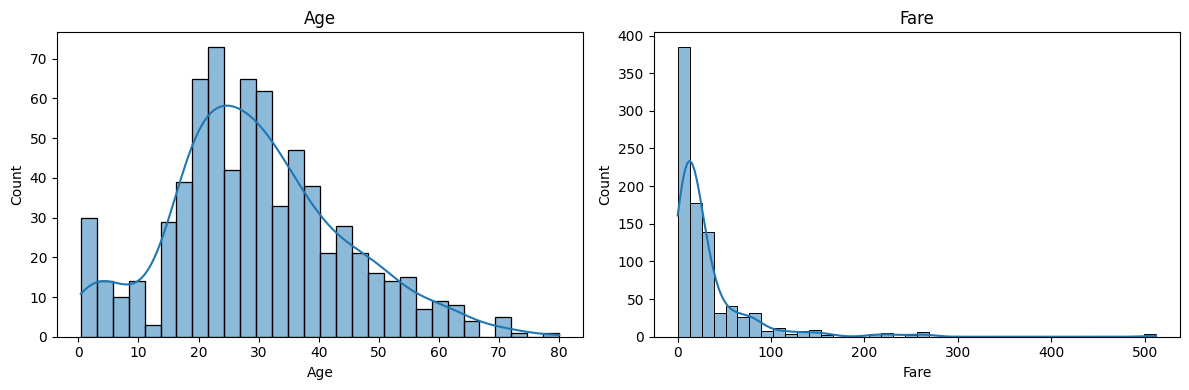

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(titanic['Age'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Age')
sns.histplot(titanic['Fare'], bins=40, kde=True, ax=axes[1])
axes[1].set_title('Fare')
plt.tight_layout()
plt.show()

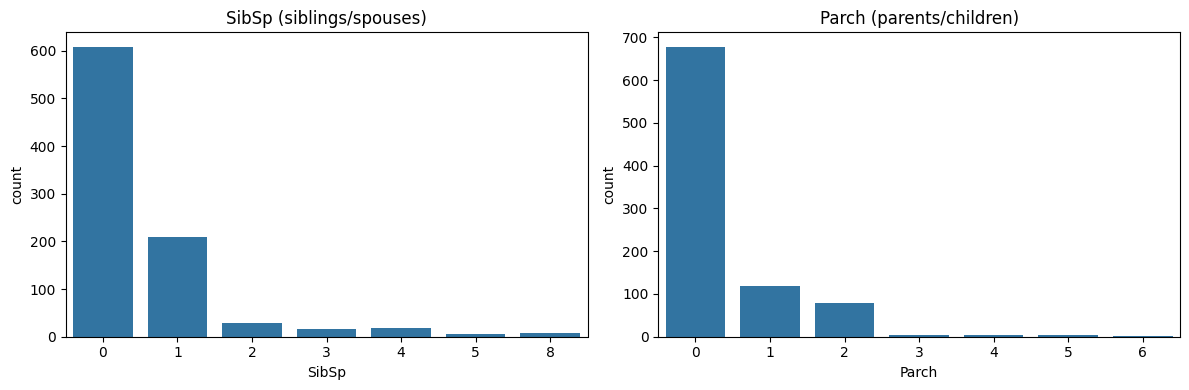

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=titanic, x='SibSp', ax=axes[0])
axes[0].set_title('SibSp (siblings/spouses)')
sns.countplot(data=titanic, x='Parch', ax=axes[1])
axes[1].set_title('Parch (parents/children)')
plt.tight_layout()
plt.show()

📝 **Questions:**
- What percentage of passengers survived?
- Is `Age` roughly normally distributed? What about `Fare`? (Keyword: skewed)
- Did most passengers travel alone or with family?

## 2. Bivariate Analysis
### Survival Rate by Category

In [19]:
for col in ['Sex', 'Pclass', 'Embarked']:
    print(titanic.groupby(col)['Survived'].mean().round(3), '\n')

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64 

Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64 

Embarked
C    0.554
Q    0.390
S    0.337
Name: Survived, dtype: float64 



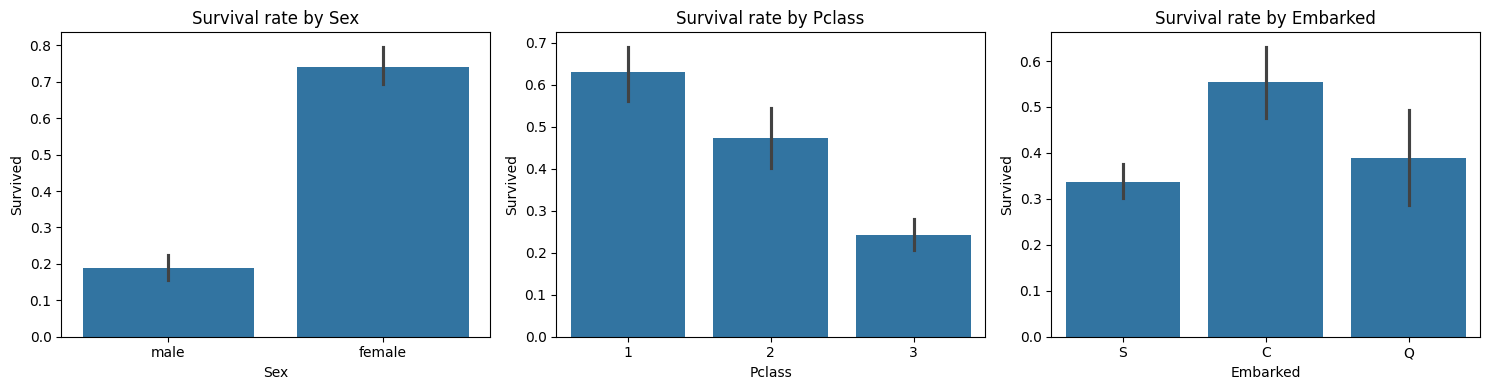

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Sex', 'Pclass', 'Embarked']):
    sns.barplot(data=titanic, x=col, y='Survived', ax=ax) # bar = survival rate
    ax.set_title('Survival rate by ' + col)
plt.tight_layout()
plt.show()

Sex **and** class combined:

In [21]:
pd.crosstab(titanic['Sex'], titanic['Pclass'], values=titanic['Survived'], aggfunc='mean').round(3)

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


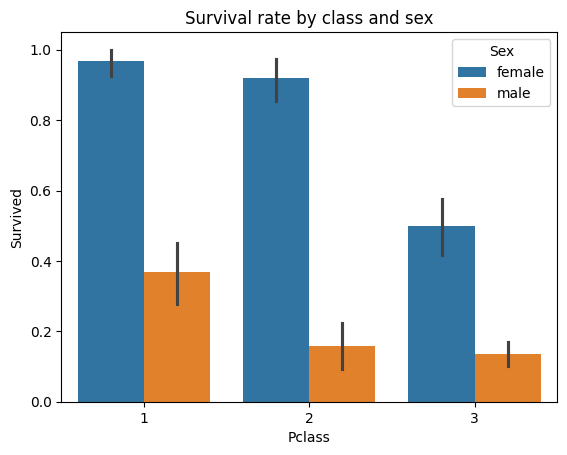

In [22]:
sns.barplot(data=titanic, x='Pclass', y='Survived', hue='Sex')
plt.title('Survival rate by class and sex')
plt.show()

### Age and Fare vs. Survival

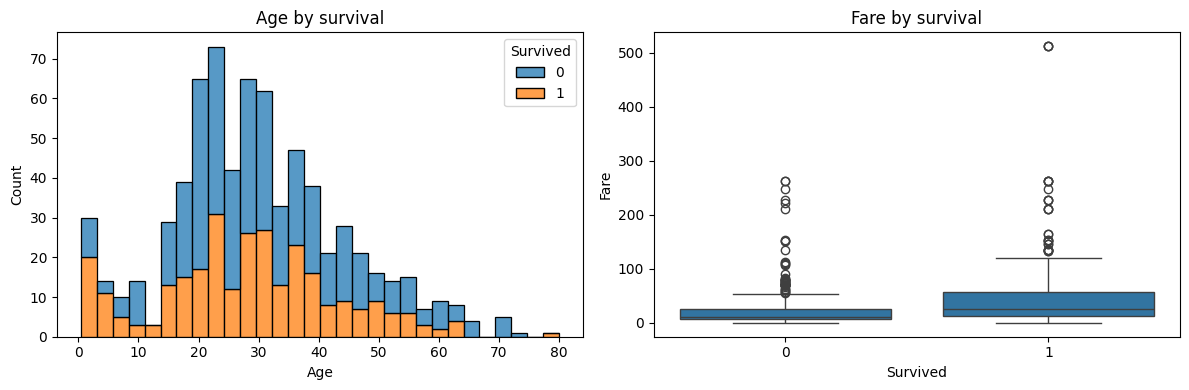

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=titanic, x='Age', hue='Survived', bins=30, multiple='stack', ax=axes[0])
axes[0].set_title('Age by survival')
sns.boxplot(data=titanic, x='Survived', y='Fare', ax=axes[1])
axes[1].set_title('Fare by survival')
plt.tight_layout()
plt.show()

### Correlations Between Numeric Variables

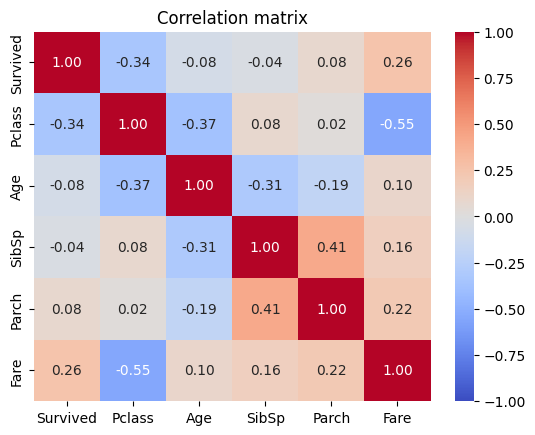

In [24]:
numeric = titanic[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']]
sns.heatmap(numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()

📝 **Questions:**
- Which variable is most strongly related to `Survived`?
- Does "women and children first" hold? Where can you see it?
- Why are `Pclass` and `Fare` negatively correlated?
- Did passengers from Cherbourg (C) survive more often? Could this be due to their class? (Hint: `pd.crosstab(titanic['Embarked'], titanic['Pclass'])`)

## 3. Outliers & Extreme Values

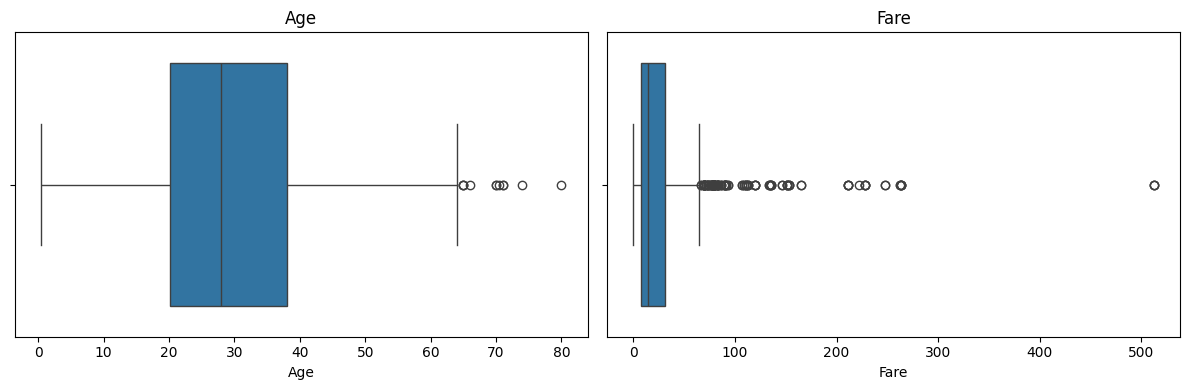

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=titanic['Age'], ax=axes[0])
axes[0].set_title('Age')
sns.boxplot(x=titanic['Fare'], ax=axes[1])
axes[1].set_title('Fare')
plt.tight_layout()
plt.show()

Outliers according to the IQR rule (values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR):

In [26]:
for col in ['Age', 'Fare']:
    q1, q3 = titanic[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = titanic[(titanic[col] < q1 - 1.5 * iqr) | (titanic[col] > q3 + 1.5 * iqr)]
    print(col, '- number of outliers:', len(outliers))

Age - number of outliers: 11
Fare - number of outliers: 116


The most expensive tickets – and the tickets that cost 0:

In [27]:
titanic.sort_values('Fare', ascending=False)[['Name', 'Pclass', 'Fare', 'Ticket', 'Survived']].head(10)

,Name,Pclass,Fare,Ticket,Survived
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,PC 17755,1
258,"Ward, Miss. Anna",1,512.3292,PC 17755,1
737,"Lesurer, Mr. Gustave J",1,512.3292,PC 17755,1
88,"Fortune, Miss. Mabel Helen",1,263.0000,19950,1
438,"Fortune, Mr. Mark",1,263.0000,19950,0
341,"Fortune, Miss. Alice Elizabeth",1,263.0000,19950,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,19950,0
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750,PC 17608,1
311,"Ryerson, Miss. Emily Borie",1,262.3750,PC 17608,1
299,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",1,247.5208,PC 17558,1


In [28]:
titanic[titanic['Fare'] == 0][['Name', 'Pclass', 'Age', 'Ticket', 'Survived']]

,Name,Pclass,Age,Ticket,Survived
179,"Leonard, Mr. Lionel",3,36.0,LINE,0
263,"Harrison, Mr. William",1,40.0,112059,0
271,"Tornquist, Mr. William Henry",3,25.0,LINE,1
277,"Parkes, Mr. Francis ""Frank""",2,NaN,239853,0
302,"Johnson, Mr. William Cahoone Jr",3,19.0,LINE,0
413,"Cunningham, Mr. Alfred Fleming",2,NaN,239853,0
466,"Campbell, Mr. William",2,NaN,239853,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,NaN,239854,0
597,"Johnson, Mr. Alfred",3,49.0,LINE,0
633,"Parr, Mr. William Henry Marsh",1,NaN,112052,0


📝 **Questions:**
- Are the high `Fare` values errors or real values (e.g. group tickets, luxury suites)? Should we delete them?
- Who paid 0? (Hint: `Ticket` = `LINE` – employees of the shipping company?)
- Is an 80-year-old passenger an outlier or plausible?

## 4. Replacing Missing Values
We work on a copy so that the original data is kept.

**Embarked** (2 missing): fill with the most frequent value (mode).

In [29]:
df = titanic.copy()
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Embarked'].isnull().sum()

np.int64(0)

**Age** (177 missing, approx. 20%): instead of one overall average we use the **median per class and sex** – this is more accurate because age differs between these groups:

In [30]:
df.groupby(['Pclass', 'Sex'])['Age'].median()

Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64

In [31]:
df['Age'] = df['Age'].fillna(df.groupby(['Pclass', 'Sex'])['Age'].transform('median'))
df['Age'].isnull().sum()

np.int64(0)

**Cabin** (687 missing, approx. 77%): too many to fill in. But we keep the information *whether* a cabin was known, and then drop the column:

In [32]:
df['HasCabin'] = df['Cabin'].notnull().astype(int)
df = df.drop(['Cabin'], axis=1)
df.groupby('HasCabin')['Survived'].mean()

,Survived
HasCabin,
0,0.299854
1,0.666667


In [33]:
df.isnull().sum() # check: no missing values left

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


📝 **Questions:**
- Why is the median better than the mean here? (Hint: outliers, skewness)
- What does `HasCabin` tell us about survival – and why might that be?

## 5. Feature Engineering
**Family size** and **travelling alone**:

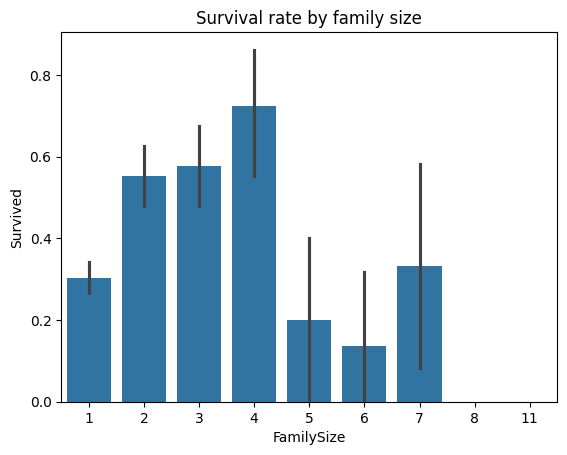

In [34]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1 # +1 for the passenger themself
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
sns.barplot(data=df, x='FamilySize', y='Survived')
plt.title('Survival rate by family size')
plt.show()

Extract the **title** from the name (e.g. "Braund, **Mr**. Owen Harris"):

In [35]:
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.')
df['Title'].value_counts()

,count
Title,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [36]:
# group rare titles together
df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
common = ['Mr', 'Mrs', 'Miss', 'Master']
df.loc[~df['Title'].isin(common), 'Title'] = 'Rare'
df.groupby('Title')['Survived'].agg(['mean', 'count']).round(3)

,mean,count
Title,,
Master,0.575,40
Miss,0.703,185
Mr,0.157,517
Mrs,0.794,126
Rare,0.348,23


**Age groups**:

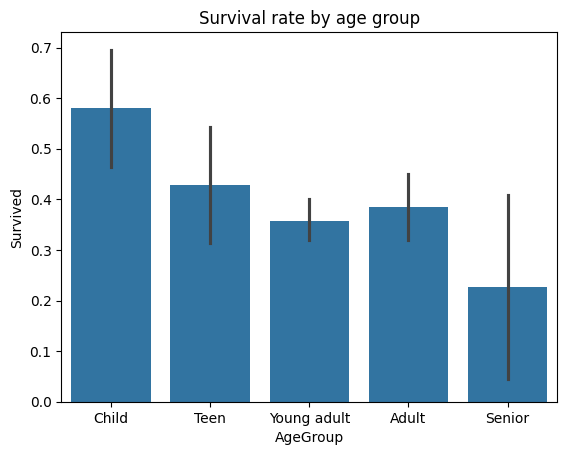

In [37]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 80],
                        labels=['Child', 'Teen', 'Young adult', 'Adult', 'Senior'])
sns.barplot(data=df, x='AgeGroup', y='Survived')
plt.title('Survival rate by age group')
plt.show()

In [38]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,HasCabin,FamilySize,IsAlone,Title,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0,2,0,Mr,Young adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1,2,0,Mrs,Adult
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0,1,1,Miss,Young adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1,2,0,Mrs,Young adult
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0,1,1,Mr,Young adult


📝 **Questions:**
- Is travelling alone good or bad for survival? What about very large families?
- What does the title "Master" mean? What is the survival rate of this group?
- Which new features would you use for a prediction model?

## Conclusion
Summarise in 3–5 sentences what you have learned about the data (data quality, most important patterns, open questions):

*…*